# Land-Use and Land-Cover Change Detection and Projection — Oyo State, Nigeria (2018–2025 → 2031)

Workflow (follows the study design): **AOI (Oyo State)→ Sentinel-2 composites (2018–2025) → Random Forest (4 classes) → accuracy assessment → change detection → Markov-CA projection to 2031 (with hindcast validation) → maps, tables, 3D built-up visualisation**


## Installation of pydeck — Setup up of required packages

In [ ]:
import importlib.util, subprocess, sys

_required = {"ee": "earthengine-api", "geemap": "geemap", "rasterio": "rasterio",
             "scipy": "scipy", "pydeck": "pydeck", "ipywidgets": "ipywidgets"}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
    print("Installed:", ", ".join(_missing))
else:
    print("All required packages are already available.")

Installed: pydeck


## Importing Libraries and Authenticating Google Earth Engine

In [ ]:
import io, os, time, html, shutil, zipfile, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ee, geemap, rasterio, requests
import pydeck as pdk
import ipywidgets as widgets
from rasterio.warp import transform as warp_transform
from scipy.ndimage import uniform_filter
from scipy.linalg import fractional_matrix_power
from IPython.display import display, HTML, clear_output

warnings.filterwarnings("ignore", category=UserWarning)

# ======================= CONFIGURATION =======================
PROJECT_ID = "gifted-electron-480321-r9"
AOI_ASSET = "projects/gifted-electron-480321-r9/assets/Oyo_State_LGA_Boundaries_Shapefile"

YEARS = list(range(2018, 2026))                  # study period 2018–2025
BASELINE_YEAR, LATEST_YEAR = YEARS[0], YEARS[-1]
PROJECTION_YEAR = 2031
TRAIN_YEAR = 2021                                # WorldCover 2021 labels match this composite
HINDCAST_CALIB_END = 2022                        # calibrate 2018→2022, predict 2025, compare with real 2025

# Seasonal window used for every year (Jan–Mar = dry season, fewer clouds)
MIN_SCENES = 15                                  # below this the window is widened to Nov–Mar
MAX_CLOUDY_PCT = 80
ALLOW_TOA_FALLBACK = False                       # True = use top-of-atmosphere data if Level-2A is missing (spectrally less consistent)

# Classification
SAMPLES_PER_CLASS = 1200                         # 4 classes x 1200 = 4,800 (< 5,000 Earth Engine getInfo limit)
TRAINING_SCALE = 30
N_TREES = 200
RANDOM_SEED = 42

# In-memory analysis grid (metres). Tried in order if Earth Engine rejects a request as too large.
CRS = "EPSG:32631"
GRID_SCALES = (100, 150, 200, 250)
MAJORITY_FILTER_SIZE = 1                         # 1 = off. Use 3 to suppress salt-and-pepper noise (may erode thin rivers/roads)

# Markov-CA projection
CA_WINDOW = 5                                    # neighbourhood window in pixels
CA_ITERATIONS = 3                                # allocation passes (growth clusters around new development)
URBAN_IS_IRREVERSIBLE = True                     # built-up land is not allowed to revert (treats Urban→other as classification noise)

# 3D built-up view
CELL_BLOCKS = 5                                  # 5 x 100 m = 500 m cells
MIN_BUILT_FRACTION = 0.05                        # hide cells with <5 % built-up
HEIGHT_M_AT_100PCT = 4000                        # column height for a fully built-up cell
BASEMAP = "dark"                                 # "dark", "light", "satellite" (satellite needs a Mapbox token)
MAPBOX_TOKEN = ""                                # optional: paste a Mapbox token for native Mapbox basemaps

# Save the small final rasters (LZW-compressed uint8 GeoTIFFs, typically < 1 MB each)?
SAVE_FINAL_RASTERS = True

# Classes
CLASS_NAMES = {1: "Vegetation", 2: "Urban/Built-up", 3: "Water", 4: "Bare Soil"}
CLASS_COLORS = {1: "#008000", 2: "#FF0000", 3: "#0000FF", 4: "#FFFF00"}
CLASS_IDS = list(CLASS_NAMES)
PALETTE = [CLASS_COLORS[c] for c in CLASS_IDS]
NAMES = [CLASS_NAMES[c] for c in CLASS_IDS]

OUTPUT_DIR = Path("/content" if Path("/content").exists() else ".") / "OyoLandCover_2018_2031"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)
print("Earth Engine initialised. Outputs ->", OUTPUT_DIR)

Earth Engine initialised. Outputs -> /content/OyoLandCover_2018_2031


## Definning AOI: Study-area preparation

In [ ]:
aoi_fc = ee.FeatureCollection(AOI_ASSET)
n_lga = aoi_fc.size().getInfo()
if n_lga == 0:
    raise ValueError("The AOI asset contains no features.")

props = aoi_fc.first().propertyNames().getInfo()
NAME_FIELD = next((p for p in ("LGA", "LGA_NAME", "LGAName", "lga", "lga_name", "NAME_2", "ADM2_NAME",
                               "shapeName", "admin2Name", "Name", "NAME", "name") if p in props), None)
LGA_NAMES = (aoi_fc.aggregate_array(NAME_FIELD).getInfo() if NAME_FIELD
             else [f"LGA_{i + 1}" for i in range(n_lga)])

AOI = aoi_fc.geometry()
AOI_BOX = AOI.bounds()

# Raster of LGA ids (1..n) so that all LGA statistics can be computed locally and instantly.
_lga_list = aoi_fc.toList(n_lga)
_indexed = ee.FeatureCollection(
    ee.List.sequence(1, n_lga).map(
        lambda i: ee.Feature(_lga_list.get(ee.Number(i).subtract(1))).set("lga_idx", i)))
LGA_IMG = (_indexed.reduceToImage(["lga_idx"], ee.Reducer.first())
           .unmask(0).toInt16().rename("lga"))

print(f"{n_lga} LGAs | name field: {NAME_FIELD} | AOI area: "
      f"{AOI.area(maxError=100).divide(1e6).getInfo():,.0f} km²")

33 LGAs | name field: None | AOI area: 27,514 km²


## Sentinel-2 acquisition and preprocessing

In [ ]:
BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]
PREDICTORS = BANDS + ["NDVI", "MNDWI", "NDBI", "BSI"]
SR_ID, TOA_ID = "COPERNICUS/S2_SR_HARMONIZED", "COPERNICUS/S2_HARMONIZED"
BAD_SCL = [0, 1, 3, 7, 8, 9, 10, 11]   # no data, saturated, shadow, unclassified, clouds, cirrus, snow


def mask_sr(img):
    valid = img.select("SCL").remap(BAD_SCL, [0] * len(BAD_SCL), 1)
    return (img.select(BANDS).multiply(0.0001).updateMask(valid)
            .copyProperties(img, ["system:time_start"]))


def mask_toa(img):
    qa = img.select("QA60")
    valid = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
    return (img.select(BANDS).multiply(0.0001).updateMask(valid)
            .copyProperties(img, ["system:time_start"]))


def add_indices(img):
    ndvi = img.normalizedDifference(["B8", "B4"]).rename("NDVI")
    mndwi = img.normalizedDifference(["B3", "B11"]).rename("MNDWI")
    ndbi = img.normalizedDifference(["B11", "B8"]).rename("NDBI")
    bsi = img.expression(
        "((SWIR + RED) - (NIR + BLUE)) / ((SWIR + RED) + (NIR + BLUE))",
        {"SWIR": img.select("B11"), "RED": img.select("B4"),
         "NIR": img.select("B8"), "BLUE": img.select("B2")}).rename("BSI")
    return img.addBands([ndvi, mndwi, ndbi, bsi])


def season_collection(year, source="SR", extended=False):
    start = ee.Date.fromYMD(year - 1, 11, 1) if extended else ee.Date.fromYMD(year, 1, 1)
    end = ee.Date.fromYMD(year, 4, 1)
    coll = (ee.ImageCollection(SR_ID if source == "SR" else TOA_ID)
            .filterBounds(AOI_BOX).filterDate(start, end)
            .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUDY_PCT)))
    return coll.map(mask_sr if source == "SR" else mask_toa)


def count_scenes(colls):
    """One round trip for many collections."""
    return ee.Dictionary({k: c.size() for k, c in colls.items()}).getInfo()


# 1) standard window for every year (single request)
colls = {str(y): season_collection(y) for y in YEARS}
counts = count_scenes(colls)
log = {y: {"source": "S2 SR", "window": "Jan–Mar", "scenes": counts[str(y)]} for y in YEARS}

# 2) widen the window where coverage is thin
short = [y for y in YEARS if counts[str(y)] < MIN_SCENES]
if short:
    ext = {str(y): season_collection(y, extended=True) for y in short}
    ext_counts = count_scenes(ext)
    for y in short:
        if ext_counts[str(y)] >= MIN_SCENES:
            colls[str(y)] = ext[str(y)]
            log[y] = {"source": "S2 SR", "window": "Nov–Mar", "scenes": ext_counts[str(y)]}

# 3) optional last resort: top-of-atmosphere imagery
still_short = [y for y in YEARS if log[y]["scenes"] < MIN_SCENES and log[y]["window"] == "Jan–Mar"]
if still_short:
    if not ALLOW_TOA_FALLBACK:
        raise ValueError(
            f"Too few Level-2A scenes for {still_short} (see table). Set ALLOW_TOA_FALLBACK = True to use "
            "top-of-atmosphere imagery for those years (spectrally less consistent), or lower MIN_SCENES.")
    toa = {str(y): season_collection(y, "TOA", extended=True) for y in still_short}
    toa_counts = count_scenes(toa)
    for y in still_short:
        colls[str(y)] = toa[str(y)]
        log[y] = {"source": "S2 TOA (fallback)", "window": "Nov–Mar", "scenes": toa_counts[str(y)]}
        print(f"WARNING {y}: Level-2A unavailable, using TOA imagery — change estimates involving {y} are less reliable.")

COMPOSITES = {y: add_indices(colls[str(y)].median()) for y in YEARS}
display(pd.DataFrame(log).T.rename_axis("year"))

,source,window,scenes
year,,,
2018,S2 SR,Jan–Mar,96
2019,S2 SR,Jan–Mar,266
2020,S2 SR,Jan–Mar,284
2021,S2 SR,Jan–Mar,264
2022,S2 SR,Jan–Mar,252
2023,S2 SR,Jan–Mar,278
2024,S2 SR,Jan–Mar,304
2025,S2 SR,Jan–Mar,248


## Random Forest land-cover classification

Training labels

In [ ]:
worldcover = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
labels = (worldcover.remap([10, 20, 30, 40, 90, 95, 100, 50, 80, 60],
                           [1, 1, 1, 1, 1, 1, 1, 2, 3, 4], 0)
          .rename("class"))

stack = COMPOSITES[TRAIN_YEAR].select(PREDICTORS).addBands(labels)
sample_fc = stack.stratifiedSample(
    numPoints=0, classBand="class", region=AOI, scale=TRAINING_SCALE, seed=RANDOM_SEED,
    classValues=CLASS_IDS, classPoints=[SAMPLES_PER_CLASS] * len(CLASS_IDS),
    dropNulls=True, tileScale=4, geometries=True)

feats = sample_fc.getInfo()["features"]
samples_df = pd.DataFrame([{**f["properties"],
                            "lon": f["geometry"]["coordinates"][0],
                            "lat": f["geometry"]["coordinates"][1]} for f in feats])
samples_df = samples_df[samples_df["class"].isin(CLASS_IDS)].reset_index(drop=True)
if len(samples_df) < 100:
    raise ValueError("Too few training samples. Inspect imagery, labels and AOI.")

# Spatial-block hold-out: ~1/5 of the 0.1° blocks are reserved for testing.
ix, iy = np.floor(samples_df["lon"] * 10), np.floor(samples_df["lat"] * 10)
samples_df["is_test"] = ((ix * 7 + iy * 13) % 5) == 0
train_df, test_df = samples_df[~samples_df["is_test"]], samples_df[samples_df["is_test"]]
print("Samples per class:", samples_df["class"].value_counts().sort_index().to_dict())
print(f"Train: {len(train_df)} | Test: {len(test_df)}")
if test_df["class"].nunique() < len(CLASS_IDS):
    print("WARNING: some classes are missing from the test blocks, so their accuracy cannot be evaluated.")


def df_to_fc(df):
    records = df[PREDICTORS + ["class", "lon", "lat"]].to_dict("records")
    features = [{"type": "Feature",
                 "geometry": {"type": "Point", "coordinates": [r["lon"], r["lat"]]},
                 "properties": {**{p: float(r[p]) for p in PREDICTORS}, "class": int(r["class"])}}
                for r in records]
    return ee.FeatureCollection({"type": "FeatureCollection", "features": features})


train_fc, test_fc = df_to_fc(train_df), df_to_fc(test_df)

rf = ee.Classifier.smileRandomForest(
    numberOfTrees=N_TREES, minLeafPopulation=2, bagFraction=0.7, seed=RANDOM_SEED
).train(train_fc, "class", PREDICTORS)

# The same trained classifier is applied to every year.
CLASSIFIED = {y: COMPOSITES[y].select(PREDICTORS).classify(rf).rename("class").toByte().clip(AOI)
              for y in YEARS}
print("Classified:", ", ".join(str(y) for y in YEARS))

Samples per class: {1: 1200, 2: 1200, 3: 1200, 4: 1200}
Train: 3309 | Test: 1491
Classified: 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025


## Accuracy assessment

In [ ]:
cm_ee = test_fc.classify(rf).errorMatrix("class", "classification", CLASS_IDS).array()
importance_ee = ee.Dictionary(rf.explain().get("importance"))
res = ee.Dictionary({"cm": cm_ee, "importance": importance_ee}).getInfo()

cm = np.array(res["cm"], dtype=float)                # rows = reference, columns = predicted
diag = np.diag(cm)
pa = np.divide(diag, cm.sum(axis=1), out=np.full(4, np.nan), where=cm.sum(axis=1) > 0)   # producer's
ua = np.divide(diag, cm.sum(axis=0), out=np.full(4, np.nan), where=cm.sum(axis=0) > 0)   # user's
f1 = 2 * pa * ua / (pa + ua)
n_test = cm.sum()
po = diag.sum() / n_test
pe = (cm.sum(axis=1) * cm.sum(axis=0)).sum() / n_test ** 2
kappa = (po - pe) / (1 - pe)

accuracy_df = pd.DataFrame({"producers_accuracy": pa, "users_accuracy": ua, "f1": f1}, index=NAMES).round(3)
display(pd.DataFrame(cm.astype(int), index=[f"ref {n}" for n in NAMES], columns=[f"pred {n}" for n in NAMES]))
display(accuracy_df)
print(f"Overall accuracy: {po:.3f} | Kappa: {kappa:.3f} | Test samples: {int(n_test)}")

imp = pd.Series(res["importance"]).sort_values(ascending=False).round(2)
print("Feature importance:", imp.to_dict())

accuracy_df.assign(overall_accuracy=po, kappa=kappa).to_csv(OUTPUT_DIR / "accuracy_assessment.csv")

,pred Vegetation,pred Urban/Built-up,pred Water,pred Bare Soil
ref Vegetation,211,6,0,4
ref Urban/Built-up,13,273,0,22
ref Water,0,0,579,55
ref Bare Soil,3,20,60,245


,producers_accuracy,users_accuracy,f1
Vegetation,0.955,0.930,0.942
Urban/Built-up,0.886,0.913,0.900
Water,0.913,0.906,0.910
Bare Soil,0.747,0.752,0.749


Overall accuracy: 0.877 | Kappa: 0.826 | Test samples: 1491
Feature importance: {'NDVI': 570.47, 'MNDWI': 541.09, 'B12': 531.26, 'B11': 525.71, 'B3': 506.26, 'B4': 502.49, 'NDBI': 493.39, 'B8': 473.26, 'B2': 464.95, 'BSI': 462.44}


## Land-cover change detection

**Streaming the classified maps into memory**  Each year is requested from Earth Engine as a GeoTIFF *byte stream* and read straight into a NumPy array.

In [ ]:
def _download(image, scale, retries=3):
    url = image.getDownloadURL({"scale": scale, "crs": CRS, "region": AOI_BOX,
                                "format": "GEO_TIFF", "filePerBand": False})
    last = None
    for attempt in range(retries):
        try:
            resp = requests.get(url, timeout=600)
            resp.raise_for_status()
            return resp.content
        except requests.RequestException as e:
            last = e
            time.sleep(3 * (attempt + 1))
    raise last


def _read_tif(content):
    if content[:2] == b"PK":                       # zipped response
        with zipfile.ZipFile(io.BytesIO(content)) as zf:
            content = zf.read(next(n for n in zf.namelist() if n.lower().endswith(".tif")))
    with rasterio.MemoryFile(content) as mf, mf.open() as src:
        return src.read(1), src.transform, src.crs


def fetch_in_memory(images, scales=GRID_SCALES, workers=4):
    """Fetch several single-band images as in-memory arrays on one common grid."""
    for scale in scales:
        try:
            with ThreadPoolExecutor(max_workers=workers) as ex:
                futures = {k: ex.submit(lambda im=im: _read_tif(_download(im, scale)))
                           for k, im in images.items()}
                return scale, {k: f.result() for k, f in futures.items()}
        except (ee.EEException, requests.RequestException) as e:
            print(f"{scale} m request failed ({type(e).__name__}: {str(e)[:120]}) -> trying a coarser grid")
    raise RuntimeError("All grid scales failed. Check the AOI, quota or network settings.")


def majority_filter(arr, size):
    if size <= 1:
        return arr
    valid, best, out = arr > 0, np.zeros(arr.shape, np.float32), arr.copy()
    for c in CLASS_IDS:
        frac = uniform_filter((arr == c).astype(np.float32), size=size, mode="nearest")
        better = frac > best
        out[better & valid] = c
        best[better] = frac[better]
    return out


_t0 = time.time()
GRID_SCALE, _fetched = fetch_in_memory({**{y: CLASSIFIED[y] for y in YEARS}, "lga": LGA_IMG})
GRID_TRANSFORM, GRID_CRS = _fetched[BASELINE_YEAR][1], _fetched[BASELINE_YEAR][2]

LC = {y: majority_filter(_fetched[y][0].astype(np.uint8), MAJORITY_FILTER_SIZE) for y in YEARS}
LGA_ID = _fetched["lga"][0].astype(np.int32)
assert len({a.shape for a in LC.values()} | {LGA_ID.shape}) == 1, "Grids differ between years."
del _fetched

PIXEL_KM2 = abs(GRID_TRANSFORM.a * GRID_TRANSFORM.e) / 1e6
print(f"Grid: {LC[BASELINE_YEAR].shape[1]} x {LC[BASELINE_YEAR].shape[0]} px @ {GRID_SCALE} m | "
      f"mapped area: {(LC[LATEST_YEAR] > 0).sum() * PIXEL_KM2:,.0f} km² | "
      f"{time.time() - _t0:.0f} s | held in memory: {sum(a.nbytes for a in LC.values()) / 1e6:.0f} MB")

100 m request failed (HTTPError: 400 Client Error: Bad Request for url: https://earthengine.googleapis.com/v1/projects/gifted-electron-480321-r9/thumbnai) -> trying a coarser grid
Grid: 1390 x 1578 px @ 150 m | mapped area: 27,459 km² | 435 s | held in memory: 18 MB


### Area statistics, gains/losses and the transition matrix

In [ ]:
def class_counts(arr):
    return np.bincount(arr.ravel(), minlength=5)[1:5]


def transition_counts(a, b):
    """4x4 matrix of pixel counts: rows = class in `a`, columns = class in `b`."""
    valid = (a > 0) & (b > 0)
    idx = (a[valid].astype(np.int64) - 1) * 4 + (b[valid].astype(np.int64) - 1)
    return np.bincount(idx, minlength=16).reshape(4, 4).astype(np.float64)


# Area per class and year
rows = []
for y in YEARS:
    cnt = class_counts(LC[y])
    for c, n in zip(CLASS_IDS, cnt):
        rows.append({"year": y, "class_id": c, "class_name": CLASS_NAMES[c],
                     "area_km2": n * PIXEL_KM2, "area_hectares": n * PIXEL_KM2 * 100,
                     "percentage": 100 * n / cnt.sum()})
area_df = pd.DataFrame(rows)
area_wide = area_df.pivot(index="year", columns="class_name", values="area_km2")[NAMES]
area_df.to_csv(OUTPUT_DIR / "annual_land_cover_area_2018_2025.csv", index=False)

# Net change, gains and losses between the first and last year
T = transition_counts(LC[BASELINE_YEAR], LC[LATEST_YEAR])
span = LATEST_YEAR - BASELINE_YEAR
change_df = pd.DataFrame({
    f"{BASELINE_YEAR}_km2": area_wide.loc[BASELINE_YEAR].values,
    f"{LATEST_YEAR}_km2": area_wide.loc[LATEST_YEAR].values,
    "gain_km2": (T.sum(axis=0) - np.diag(T)) * PIXEL_KM2,
    "loss_km2": (T.sum(axis=1) - np.diag(T)) * PIXEL_KM2}, index=NAMES)
change_df["net_change_km2"] = change_df["gain_km2"] - change_df["loss_km2"]
change_df["net_change_%"] = 100 * change_df["net_change_km2"] / change_df[f"{BASELINE_YEAR}_km2"]
change_df["net_km2_per_year"] = change_df["net_change_km2"] / span
change_df.round(2).to_csv(OUTPUT_DIR / f"gains_losses_{BASELINE_YEAR}_{LATEST_YEAR}.csv")

# Transition matrix (km²) and ranked conversions
trans_km2 = pd.DataFrame(T * PIXEL_KM2, index=[f"from {n}" for n in NAMES], columns=[f"to {n}" for n in NAMES])
trans_long = pd.DataFrame([{"from_class": NAMES[i], "to_class": NAMES[j], "area_km2": T[i, j] * PIXEL_KM2}
                           for i in range(4) for j in range(4) if i != j]
                          ).sort_values("area_km2", ascending=False)
trans_km2.round(2).to_csv(OUTPUT_DIR / f"transition_matrix_{BASELINE_YEAR}_{LATEST_YEAR}.csv")

display(area_wide.round(1))
display(change_df.round(2))
display(trans_km2.round(1))
print("Largest conversions (km²):")
display(trans_long.head(6).round(1).reset_index(drop=True))

class_name,Vegetation,Urban/Built-up,Water,Bare Soil
year,,,,
2018,26633.9,743.6,37.3,45.0
2019,26337.0,1037.1,37.5,48.2
2020,26389.0,995.4,35.4,40.0
2021,25801.4,1491.9,33.9,132.5
2022,26230.6,1136.5,33.3,59.3
2023,26539.3,836.6,37.9,46.0
2024,26576.6,799.7,36.0,47.5
2025,26600.4,771.5,38.3,48.7


,2018_km2,2025_km2,gain_km2,loss_km2,net_change_km2,net_change_%,net_km2_per_year
Vegetation,26633.90,26600.36,195.91,229.23,-33.32,-0.13,-4.76
Urban/Built-up,743.58,771.48,206.53,178.63,27.90,3.75,3.99
Water,37.30,38.34,1.71,0.61,1.10,2.96,0.16
Bare Soil,45.00,48.69,33.16,28.84,4.32,9.60,0.62


,to Vegetation,to Urban/Built-up,to Water,to Bare Soil
from Vegetation,26404.4,203.3,0.1,25.9
from Urban/Built-up,171.9,565.0,0.0,6.7
from Water,0.0,0.0,36.6,0.6
from Bare Soil,23.9,3.3,1.6,15.5


Largest conversions (km²):


,from_class,to_class,area_km2
0,Vegetation,Urban/Built-up,203.3
1,Urban/Built-up,Vegetation,171.9
2,Vegetation,Bare Soil,25.9
3,Bare Soil,Vegetation,23.9
4,Urban/Built-up,Bare Soil,6.7
5,Bare Soil,Urban/Built-up,3.3


## LGA-level statistics: Top 10 LGAs with urban expansion

In [ ]:
def lga_class_km2(arr):
    """(n_lga x 4) class areas in km² for every LGA."""
    idx = LGA_ID * 5 + arr                       # int32 id * 5 + class
    cnt = np.bincount(idx.ravel(), minlength=(len(LGA_NAMES) + 1) * 5).reshape(-1, 5)
    return cnt[1:, 1:] * PIXEL_KM2


lga_base, lga_last = lga_class_km2(LC[BASELINE_YEAR]), lga_class_km2(LC[LATEST_YEAR])
U, V = CLASS_IDS.index(2), CLASS_IDS.index(1)
lga_df = pd.DataFrame({
    "LGA": LGA_NAMES,
    f"urban_{BASELINE_YEAR}_km2": lga_base[:, U], f"urban_{LATEST_YEAR}_km2": lga_last[:, U],
    "urban_gain_km2": lga_last[:, U] - lga_base[:, U],
    f"vegetation_{BASELINE_YEAR}_km2": lga_base[:, V], f"vegetation_{LATEST_YEAR}_km2": lga_last[:, V],
    "vegetation_change_km2": lga_last[:, V] - lga_base[:, V],
    f"urban_share_{LATEST_YEAR}_%": 100 * lga_last[:, U] / lga_last.sum(axis=1).clip(min=1e-9)})
lga_df = lga_df.sort_values("urban_gain_km2", ascending=False).reset_index(drop=True)
lga_df.round(2).to_csv(OUTPUT_DIR / f"lga_statistics_{BASELINE_YEAR}_{LATEST_YEAR}.csv", index=False)
print(f"Top 10 LGAs by built-up expansion, {BASELINE_YEAR}–{LATEST_YEAR}:")
display(lga_df.head(10).round(2))

Top 10 LGAs by built-up expansion, 2018–2025:


,LGA,urban_2018_km2,urban_2025_km2,urban_gain_km2,vegetation_2018_km2,vegetation_2025_km2,vegetation_change_km2,urban_share_2025_%
0,LGA_16,48.78,99.22,50.44,1032.48,981.97,-50.51,9.17
1,LGA_17,69.14,92.00,22.86,411.12,388.15,-22.97,19.11
2,LGA_27,58.66,67.79,9.14,698.74,691.36,-7.38,8.90
3,LGA_25,47.59,55.08,7.49,263.74,255.40,-8.35,17.65
4,LGA_24,29.41,35.62,6.21,9.07,2.90,-6.16,91.50
5,LGA_15,4.32,10.10,5.78,1239.95,1229.49,-10.46,0.81
6,LGA_11,34.20,39.31,5.11,488.99,483.23,-5.76,7.50
7,LGA_22,16.38,19.93,3.56,11.09,7.54,-3.56,71.92
8,LGA_19,6.57,9.94,3.38,449.48,445.23,-4.25,2.18
9,LGA_32,11.23,13.64,2.41,702.32,699.44,-2.88,1.91


## Urban gain statistics

In [ ]:
import pandas as pd

# Calculate summary metrics for urban gain across LGAs
total_gain = lga_df['urban_gain_km2'].sum()
mean_gain = lga_df['urban_gain_km2'].mean()
median_gain = lga_df['urban_gain_km2'].median()
max_gain = lga_df['urban_gain_km2'].max()
top_lga = lga_df.loc[lga_df['urban_gain_km2'].idxmax(), 'LGA']

print("=== LGA Urban Gain Summary Statistics (2018 - 2025) ===")
print(f"Total Urban Gain across all LGAs: {total_gain:.2f} km²")
print(f"Average Urban Gain per LGA:       {mean_gain:.2f} km²")
print(f"Median Urban Gain per LGA:        {median_gain:.2f} km²")
print(f"Maximum Urban Gain in a single LGA: {max_gain:.2f} km² ({top_lga})")

print("\nTop 5 LGAs by Urban Gain (km²):")
display(lga_df[['LGA', 'urban_2018_km2', 'urban_2025_km2', 'urban_gain_km2', 'urban_share_2025_%']].head(5))

=== LGA Urban Gain Summary Statistics (2018 - 2025) ===
Total Urban Gain across all LGAs: 27.90 km²
Average Urban Gain per LGA:       0.85 km²
Median Urban Gain per LGA:        0.07 km²
Maximum Urban Gain in a single LGA: 50.44 km² (LGA_16)

Top 5 LGAs by Urban Gain (km²):


,LGA,urban_2018_km2,urban_2025_km2,urban_gain_km2,urban_share_2025_%
0,LGA_16,48.7800,99.2250,50.4450,9.171069
1,LGA_17,69.1425,92.0025,22.8600,19.107477
2,LGA_27,58.6575,67.7925,9.1350,8.900245
3,LGA_25,47.5875,55.0800,7.4925,17.648331
4,LGA_24,29.4075,35.6175,6.2100,91.502890


## Visualization for top 10 LGAs with urban growth

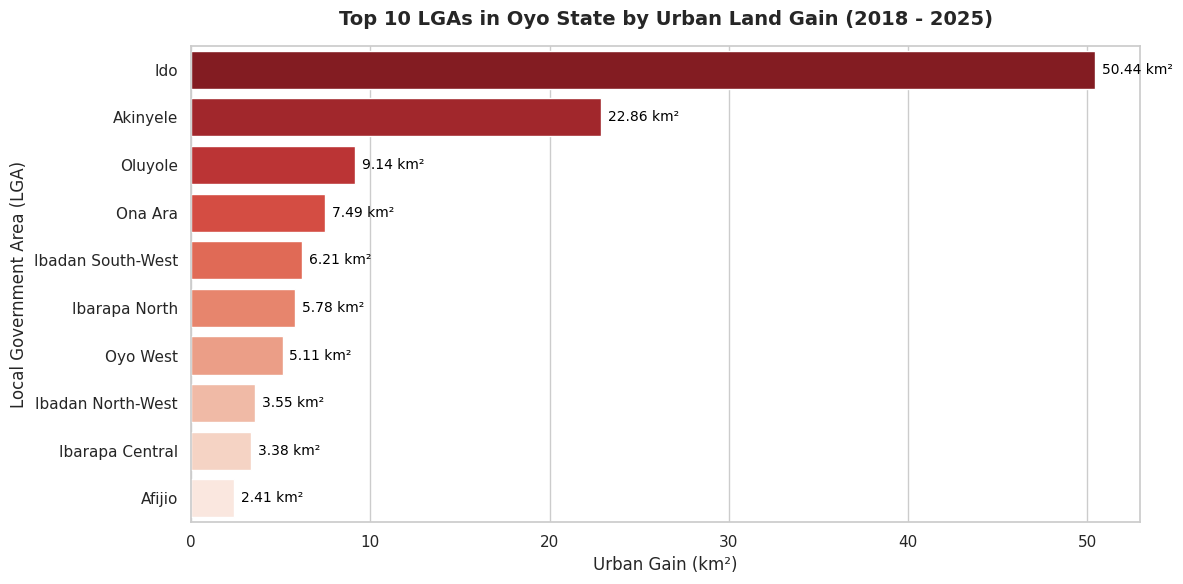

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Map placeholder names back to actual LGA names from the attribute table
try:
    actual_names = aoi_fc.aggregate_array('LGA_Name').getInfo()
    name_mapping = {f"LGA_{i+1}": actual_names[i] for i in range(len(actual_names))}
except Exception:
    name_mapping = {l: l for l in lga_df["LGA"].unique()}

# Create a copy with real names for plotting
hist_plot_df = lga_df.copy()
hist_plot_df["LGA_Real_Name"] = hist_plot_df["LGA"].map(name_mapping)

# Extract top 10 LGAs with the highest historical urban gain
top_10_gain = hist_plot_df.head(10)

# Initialize the matplotlib figure
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Create horizontal bar plot
ax = sns.barplot(
    x="urban_gain_km2",
    y="LGA_Real_Name",
    data=top_10_gain,
    palette="Reds_r",
    hue="LGA_Real_Name",
    legend=False
)

# Add data labels on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f km²", padding=5, fontsize=10, color="black")

# Set chart details
plt.title("Top 10 LGAs in Oyo State by Urban Land Gain (2018 - 2025)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Urban Gain (km²)", fontsize=12)
plt.ylabel("Local Government Area (LGA)", fontsize=12)
plt.tight_layout()

# Display visual
plt.show()

## Visualization showing projected urban land gain by 2031

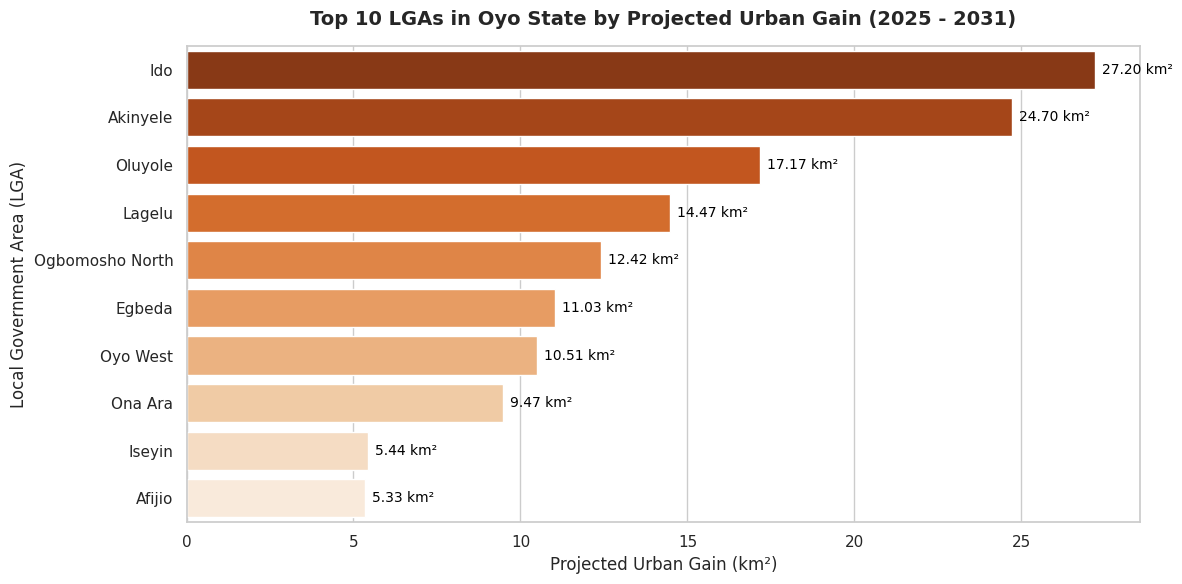

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Map placeholder names back to actual LGA names from the attribute table
try:
    actual_names = aoi_fc.aggregate_array('LGA_Name').getInfo()
    name_mapping = {f"LGA_{i+1}": actual_names[i] for i in range(len(actual_names))}
except Exception:
    name_mapping = {l: l for l in lga_df["LGA"].unique()}

# Create a copy with real names for plotting
proj_plot_df = lga_df.copy()
proj_plot_df["LGA_Real_Name"] = proj_plot_df["LGA"].map(name_mapping)

# Sort the DataFrame by projected urban gain (2025 to 2031) and get the top 10
top_10_projected = proj_plot_df.sort_values("projected_urban_gain_2025_2031_km2", ascending=False).head(10)

# Initialize the matplotlib figure
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Create a horizontal bar plot
ax = sns.barplot(
    x="projected_urban_gain_2025_2031_km2",
    y="LGA_Real_Name",
    data=top_10_projected,
    palette="Oranges_r",
    hue="LGA_Real_Name",
    legend=False
)

# Add data labels to each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f km²", padding=5, fontsize=10, color="black")

# Set chart title and labels
plt.title("Top 10 LGAs in Oyo State by Projected Urban Gain (2025 - 2031)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Projected Urban Gain (km²)", fontsize=12)
plt.ylabel("Local Government Area (LGA)", fontsize=12)
plt.tight_layout()

# Display the plot
plt.show()

## Visualization showing comparism of both historical and projected data for top 10 LGAs with land gain

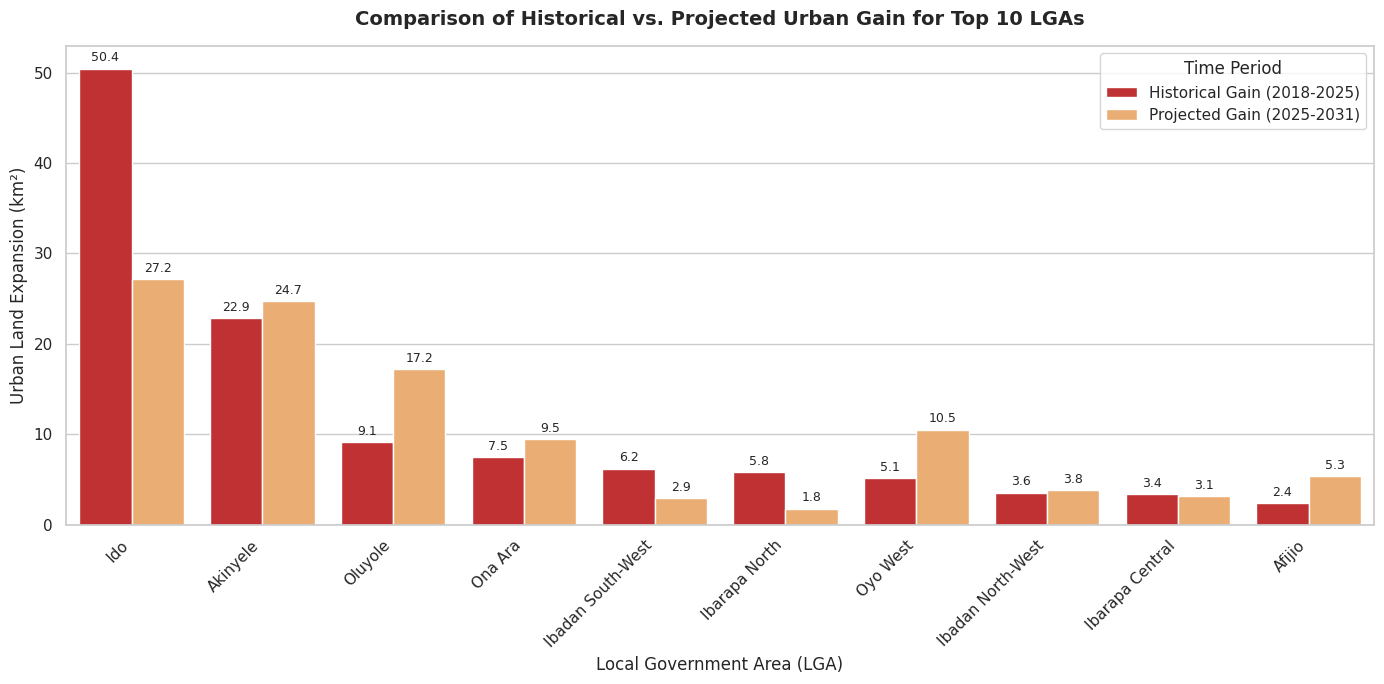

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Map placeholder names back to actual LGA names from the attribute table
# Since NAME_FIELD fell back, we can fetch the actual names from 'LGA_Name' in the FeatureCollection metadata
try:
    actual_names = aoi_fc.aggregate_array('LGA_Name').getInfo()
    name_mapping = {f"LGA_{i+1}": actual_names[i] for i in range(len(actual_names))}
except Exception:
    # Fallback if connection fails
    name_mapping = {l: l for l in lga_df["LGA"].unique()}

# Create a copy with replaced names for plotting
plot_df = lga_df.copy()
plot_df["LGA_Real_Name"] = plot_df["LGA"].map(name_mapping)

# Get top 10 LGAs by historical gain using real names
top_lgas_list = plot_df.sort_values("urban_gain_km2", ascending=False).head(10)["LGA_Real_Name"].tolist()
compare_df = plot_df[plot_df["LGA_Real_Name"].isin(top_lgas_list)].copy()

# Melt the DataFrame to long format for side-by-side plotting with seaborn
melted_df = compare_df.melt(
    id_vars=["LGA_Real_Name"],
    value_vars=["urban_gain_km2", "projected_urban_gain_2025_2031_km2"],
    var_name="Period",
    value_name="Gain_km2"
)

# Rename periods for cleaner legend labels
melted_df["Period"] = melted_df["Period"].map({
    "urban_gain_km2": "Historical Gain (2018-2025)",
    "projected_urban_gain_2025_2031_km2": "Projected Gain (2025-2031)"
})

# Create the side-by-side bar chart
plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x="LGA_Real_Name",
    y="Gain_km2",
    hue="Period",
    data=melted_df,
    palette=["#d7191c", "#fdae61"]
)

# Add labels to the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3, fontsize=9)

plt.title("Comparison of Historical vs. Projected Urban Gain for Top 10 LGAs", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Local Government Area (LGA)", fontsize=12)
plt.ylabel("Urban Land Expansion (km²)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Time Period", frameon=True)
plt.tight_layout()

# Save visual and show
plt.savefig(OUTPUT_DIR / "historical_vs_projected_urban_gain.png", dpi=120, bbox_inches="tight")
plt.show()

## Visualizations: Maps and charts

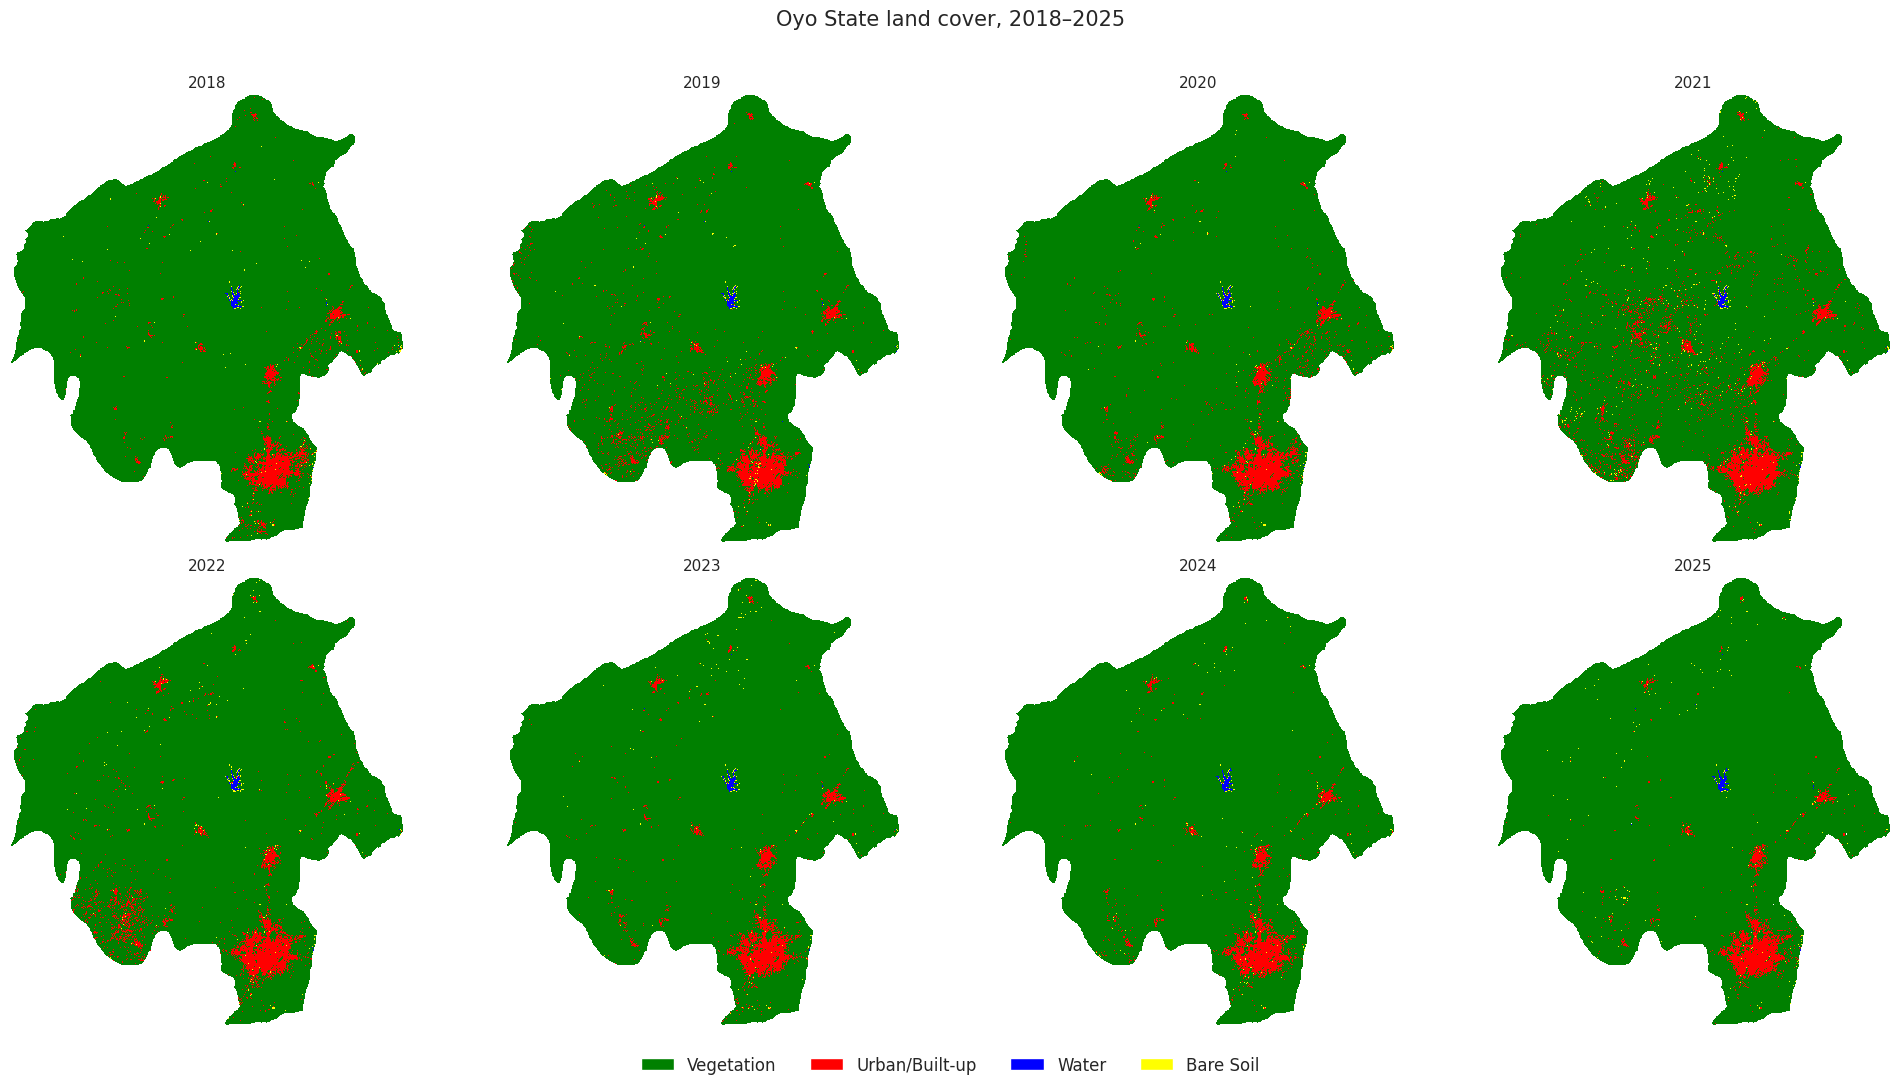

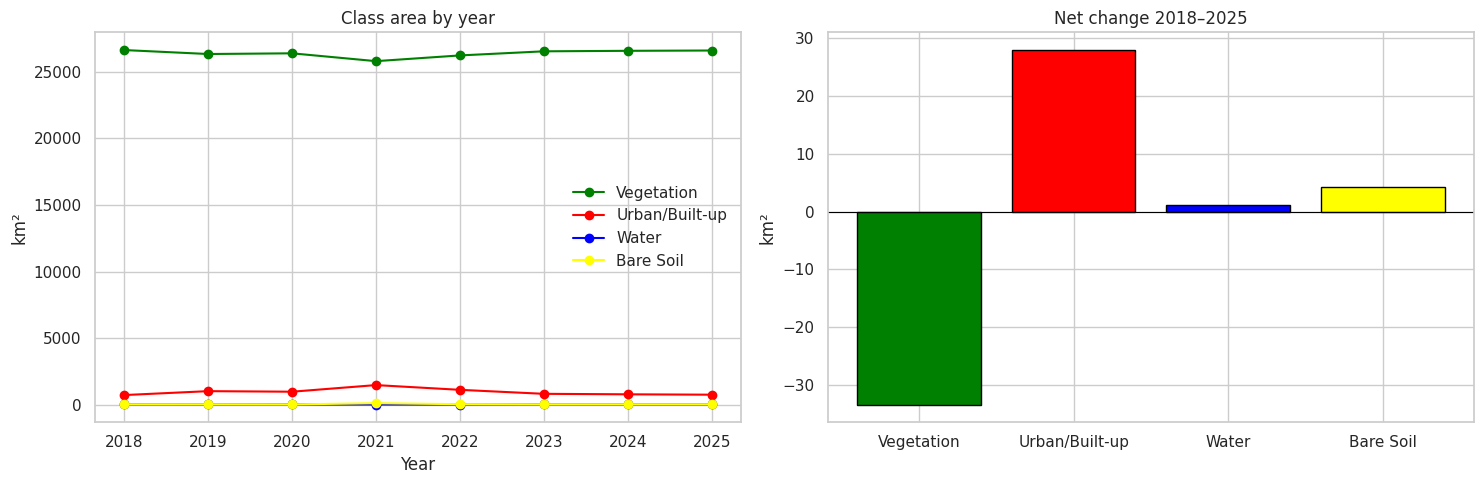

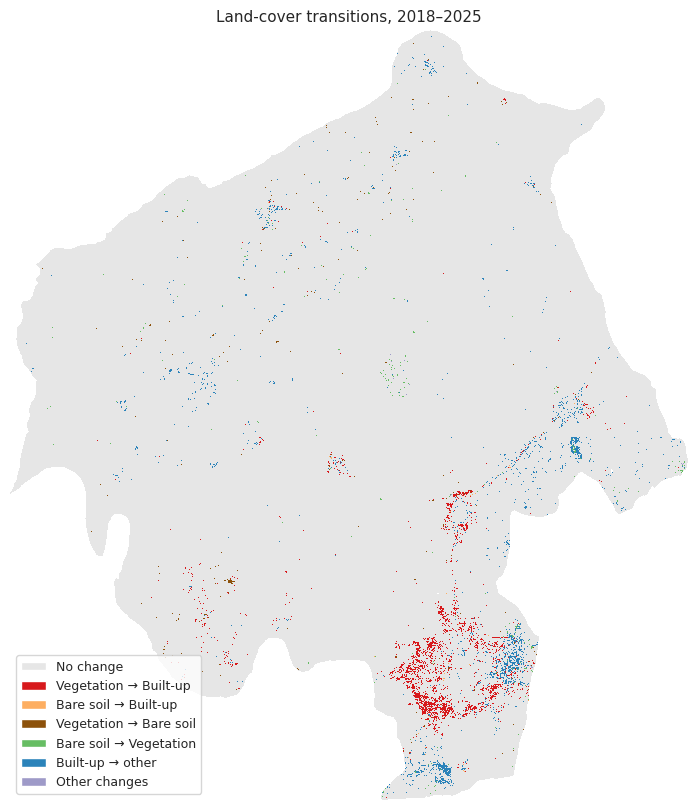

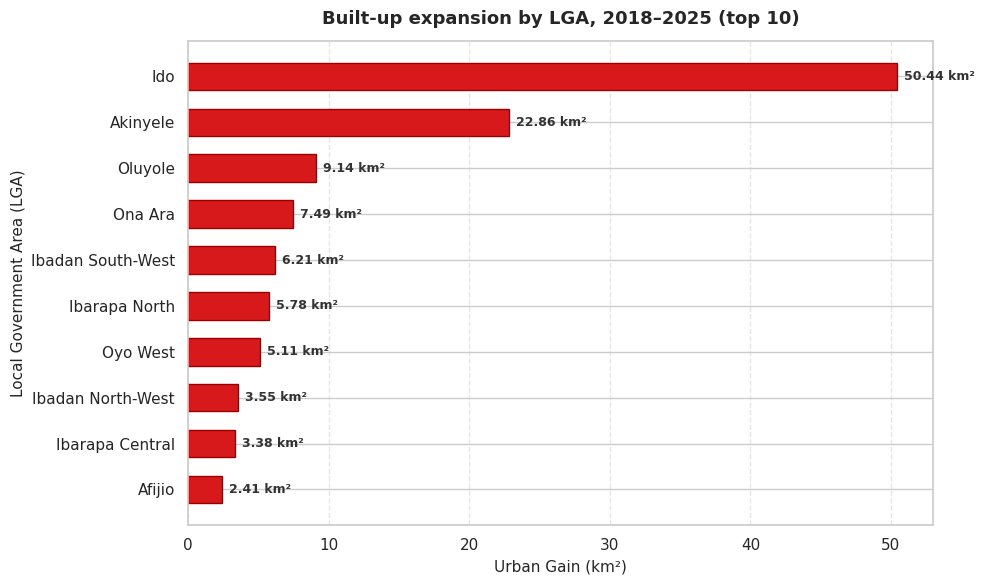

In [ ]:
def make_lut(colors):
    lut = np.zeros((256, 4), np.uint8)                 # index 0 (no data) stays transparent
    for i, col in colors.items():
        lut[i] = [int(col[j:j + 2], 16) for j in (1, 3, 5)] + [255]
    return lut


LC_LUT = make_lut(CLASS_COLORS)
legend_handles = [plt.Rectangle((0, 0), 1, 1, fc=CLASS_COLORS[c]) for c in CLASS_IDS]


def draw(ax, arr, title, lut=LC_LUT, stride=1):
    ax.imshow(lut[arr[::stride, ::stride]], interpolation="nearest")
    ax.set_title(title, fontsize=11)
    ax.axis("off")


# All study years in one figure
fig, axes = plt.subplots(2, 4, figsize=(20, 11))
for ax, y in zip(axes.ravel(), YEARS):
    draw(ax, LC[y], str(y), stride=2)
fig.legend(legend_handles, NAMES, loc="lower center", ncol=4, frameon=False, fontsize=12)
fig.suptitle("Oyo State land cover, 2018–2025", fontsize=15)
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
fig.savefig(OUTPUT_DIR / "Oyo_LandCover_2018_2025_panel.png", dpi=110, bbox_inches="tight")
plt.show()

# Area trends and net change
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for c in CLASS_IDS:
    axes[0].plot(area_wide.index, area_wide[CLASS_NAMES[c]], marker="o", color=CLASS_COLORS[c], label=CLASS_NAMES[c])
axes[0].set(title="Class area by year", xlabel="Year", ylabel="km²")
axes[0].legend(frameon=False)
axes[1].bar(NAMES, change_df["net_change_km2"], color=PALETTE, edgecolor="black")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(title=f"Net change {BASELINE_YEAR}–{LATEST_YEAR}", ylabel="km²")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "area_trends.png", dpi=120, bbox_inches="tight")
plt.show()

# Spatial distribution of the main transitions
a, b = LC[BASELINE_YEAR], LC[LATEST_YEAR]
both = (a > 0) & (b > 0)
cat = np.zeros(a.shape, np.uint8)
cat[both & (a == b)] = 1
cat[both & (a != b)] = 7                                   # other changes
cat[both & (a == 1) & (b == 2)] = 2                        # vegetation → built-up
cat[both & (a == 4) & (b == 2)] = 3                        # bare soil → built-up
cat[both & (a == 1) & (b == 4)] = 4                        # vegetation → bare soil
cat[both & (a == 4) & (b == 1)] = 5                        # bare soil → vegetation
cat[both & (a == 2) & (b != 2)] = 6                        # built-up lost
TRANS_COLORS = {1: "#E6E6E6", 2: "#D7191C", 3: "#FDAE61", 4: "#8C510A", 5: "#66BD63", 6: "#2B83BA", 7: "#9E9AC8"}
TRANS_LABELS = ["No change", "Vegetation → Built-up", "Bare soil → Built-up", "Vegetation → Bare soil",
                "Bare soil → Vegetation", "Built-up → other", "Other changes"]
fig, ax = plt.subplots(figsize=(10, 10))
draw(ax, cat, f"Land-cover transitions, {BASELINE_YEAR}–{LATEST_YEAR}", lut=make_lut(TRANS_COLORS))
ax.legend([plt.Rectangle((0, 0), 1, 1, fc=TRANS_COLORS[i]) for i in range(1, 8)], TRANS_LABELS,
          loc="lower left", frameon=True, fontsize=9)
fig.savefig(OUTPUT_DIR / f"transitions_{BASELINE_YEAR}_{LATEST_YEAR}.png", dpi=130, bbox_inches="tight")
plt.show()
CHANGE_CODE = np.where(both, a * 10 + b, 0).astype(np.uint8)   # from*10 + to

# Map placeholder names to actual LGA names for plotting
try:
    actual_names = aoi_fc.aggregate_array('LGA_Name').getInfo()
    name_mapping = {f"LGA_{i+1}": actual_names[i] for i in range(len(actual_names))}
except Exception:
    name_mapping = {l: l for l in lga_df["LGA"].unique()}

# Top LGAs by built-up expansion using actual mapped names
top = lga_df.head(10).copy()
top["LGA_Name"] = top["LGA"].map(name_mapping)
top = top.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top["LGA_Name"], top["urban_gain_km2"], color="#D7191C", edgecolor="#990000", height=0.6)
ax.set_title(f"Built-up expansion by LGA, {BASELINE_YEAR}–{LATEST_YEAR} (top 10)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Urban Gain (km²)", fontsize=11)
ax.set_ylabel("Local Government Area (LGA)", fontsize=11)
ax.grid(axis="x", linestyle="--", alpha=0.5)

# Annotate the actual expansion value at the end of each bar
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2, f"{width:.2f} km²",
            va="center", ha="left", fontsize=9, fontweight="bold", color="#333333")

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "lga_urban_gain_top10.png", dpi=120, bbox_inches="tight")
plt.show()

## Projection to 2031 (Markov chain + cellular automata)

1. **Markov chain**: the observed 2018→2025 transition matrix is rescaled to the 6-year projection horizon. This gives *how much* of each conversion is expected.
2. **Cellular automata**: those quantities are allocated *where* they are most likely, ranking candidate pixels by the share of the target class in their neighbourhood and re-computing neighbourhoods over several passes, so development clusters around existing development.
3. **Hindcast validation**: the same procedure is calibrated on 2018→2022, used to simulate 2025 from the 2022 map, and compared with the real 2025 map and with a "nothing changes" baseline.

The 2031 map is a model-based scenario under stated assumptions, not a prediction of what will happen.

In [ ]:
def prob_matrix(counts):
    """Row-normalised transition probabilities (empty rows stay in place)."""
    totals = counts.sum(axis=1, keepdims=True)
    P = np.divide(counts, totals, out=np.zeros_like(counts), where=totals > 0)
    empty = totals[:, 0] == 0
    P[empty] = np.eye(4)[empty]
    return P


def _normalise(M):
    M = np.clip(np.real(M), 0, None)
    s = M.sum(axis=1, keepdims=True)
    return np.divide(M, s, out=np.eye(4), where=s > 0)


def rescale_matrix(P, ratio):
    """P^ratio for a calibration interval rescaled to another horizon (ratio = horizon / calibration span)."""
    try:
        M = fractional_matrix_power(P, ratio)
        ok = np.isfinite(M).all() and np.abs(np.imag(M)).max() < 1e-6 and np.real(M).min() > -1e-6
    except Exception:
        ok = False
    if ok:
        return _normalise(M)
    if ratio <= 1:                                   # always a valid stochastic matrix
        return _normalise((1 - ratio) * np.eye(4) + ratio * P)
    return _normalise(np.linalg.matrix_power(P, max(1, int(round(ratio)))))


def apply_rules(P):
    P = P.copy()
    if URBAN_IS_IRREVERSIBLE:
        P[CLASS_IDS.index(2)] = np.eye(4)[CLASS_IDS.index(2)]
    return P


def ca_markov_project(current, P, window=CA_WINDOW, iterations=CA_ITERATIONS, seed=RANDOM_SEED):
    """Allocate Markov-derived quotas spatially. Conversions to Urban are allocated first."""
    rng = np.random.default_rng(seed)
    out = current.copy()
    counts = class_counts(current)
    quota = {(a, b): counts[a - 1] * P[a - 1, b - 1] for a in CLASS_IDS for b in CLASS_IDS if a != b}
    done = {k: 0 for k in quota}
    jitter = (rng.random(current.shape, dtype=np.float32) * 1e-3).ravel()   # breaks ties without spatial bias
    for it in range(iterations):
        neigh = {c: uniform_filter((out == c).astype(np.float32), size=window, mode="nearest").ravel()
                 for c in CLASS_IDS}
        new = out.copy()
        new_flat, out_flat = new.reshape(-1), out.reshape(-1)
        taken = np.zeros(out_flat.shape, bool)
        for b in (2, 3, 4, 1):                                              # priority order of target classes
            for a in CLASS_IDS:
                if a == b or quota[(a, b)] <= 0:
                    continue
                n = int(round(quota[(a, b)] * (it + 1) / iterations)) - done[(a, b)]
                cand = np.flatnonzero((out_flat == a) & ~taken)
                if n <= 0 or cand.size == 0:
                    continue
                n = min(n, cand.size)
                score = neigh[b][cand] + jitter[cand]
                sel = cand if n == cand.size else cand[np.argpartition(score, -n)[-n:]]
                new_flat[sel], taken[sel] = b, True
                done[(a, b)] += sel.size
        out = new
    return out


def agreement_stats(actual, sim):
    C = transition_counts(actual, sim)
    n = C.sum()
    po = np.trace(C) / n
    pe = (C.sum(axis=0) * C.sum(axis=1)).sum() / n ** 2
    return po, (po - pe) / (1 - pe)


def hindcast_report(start, sim, actual):
    valid = (start > 0) & (actual > 0)
    po_s, k_s = agreement_stats(actual[valid], sim[valid])
    po_p, k_p = agreement_stats(actual[valid], start[valid])
    obs, mod = valid & (actual != start), valid & (sim != start)
    hits = (obs & mod & (sim == actual)).sum()
    wrong = (obs & mod & (sim != actual)).sum()
    miss, false_alarm = (obs & ~mod).sum(), (~obs & mod).sum()
    fom = hits / max(hits + wrong + miss + false_alarm, 1)
    return {"model_agreement": po_s, "model_kappa": k_s, "baseline_agreement": po_p, "baseline_kappa": k_p,
            "figure_of_merit": fom, "observed_change_%": 100 * obs.sum() / valid.sum(),
            "simulated_change_%": 100 * mod.sum() / valid.sum()}


# ---- Hindcast: calibrate 2018→2022, simulate 2025 from the 2022 map ----
HC_START = HINDCAST_CALIB_END
P_cal = prob_matrix(transition_counts(LC[BASELINE_YEAR], LC[HC_START]))
P_hc = apply_rules(rescale_matrix(P_cal, (LATEST_YEAR - HC_START) / (HC_START - BASELINE_YEAR)))
sim_latest = ca_markov_project(LC[HC_START], P_hc)

hc = hindcast_report(LC[HC_START], sim_latest, LC[LATEST_YEAR])
hc_areas = pd.DataFrame({
    f"actual_{LATEST_YEAR}_km2": class_counts(LC[LATEST_YEAR]) * PIXEL_KM2,
    "simulated_km2": class_counts(sim_latest) * PIXEL_KM2,
    f"no_change_baseline_{HC_START}_km2": class_counts(LC[HC_START]) * PIXEL_KM2}, index=NAMES)
hc_areas["model_error_%"] = 100 * (hc_areas["simulated_km2"] / hc_areas[f"actual_{LATEST_YEAR}_km2"] - 1)
hc_areas["baseline_error_%"] = 100 * (hc_areas[f"no_change_baseline_{HC_START}_km2"] / hc_areas[f"actual_{LATEST_YEAR}_km2"] - 1)
print(f"Hindcast: calibrated {BASELINE_YEAR}→{HC_START}, simulated {LATEST_YEAR}")
display(pd.Series(hc).round(3).to_frame("value"))
display(hc_areas.round(1))
pd.Series(hc).to_csv(OUTPUT_DIR / "hindcast_validation.csv", header=["value"])
hc_areas.round(2).to_csv(OUTPUT_DIR / "hindcast_areas.csv")
print("Interpretation: the model is useful only if its agreement/kappa/figure of merit beat the no-change baseline "
      "or its area errors are smaller. Annual maps carry classification noise, so treat modest scores with care.")

Hindcast: calibrated 2018→2022, simulated 2025


,value
model_agreement,0.967
model_kappa,0.619
baseline_agreement,0.979
baseline_kappa,0.715
figure_of_merit,0.052
observed_change_%,2.095
simulated_change_%,1.600


,actual_2025_km2,simulated_km2,no_change_baseline_2022_km2,model_error_%,baseline_error_%
Vegetation,26600.4,25834.1,26230.6,-2.9,-1.4
Urban/Built-up,771.5,1535.6,1136.5,99.1,47.3
Water,38.3,30.8,33.3,-19.6,-13.0
Bare Soil,48.7,59.2,59.3,21.7,21.9


Interpretation: the model is useful only if its agreement/kappa/figure of merit beat the no-change baseline or its area errors are smaller. Annual maps carry classification noise, so treat modest scores with care.


,to Vegetation,to Urban/Built-up,to Water,to Bare Soil
from Vegetation,0.993,0.007,0.000,0.001
from Urban/Built-up,0.000,1.000,0.000,0.000
from Water,0.001,0.000,0.986,0.013
from Bare Soil,0.462,0.063,0.032,0.443


,area_2025_km2,area_2031_projected_km2,net_change_km2,net_change_%,scenario_min_km2,scenario_max_km2
Vegetation,26600.4,26426.7,-173.7,-0.7,25834.0,26535.6
Urban/Built-up,771.5,948.6,177.1,23.0,856.6,1534.2
Water,38.3,39.4,1.1,2.8,32.5,40.0
Bare Soil,48.7,44.2,-4.5,-9.2,26.6,58.2


,Full period 2018–2025,Recent 2021–2025,Early 2018–2022
"Markov scenarios, km²",,,
Vegetation,26426.7,26535.6,25834.0
Urban/Built-up,948.6,856.6,1534.2
Water,39.4,40.0,32.5
Bare Soil,44.2,26.6,58.2


LGAs projected to see the largest built-up growth, 2025–2031:


,LGA,urban_2025_km2,urban_2031_projected_km2,projected_urban_gain_2025_2031_km2
0,LGA_16,99.22,126.43,27.20
1,LGA_17,92.00,116.71,24.70
2,LGA_27,67.79,84.96,17.17
30,LGA_18,71.66,86.13,14.47
24,LGA_8,34.18,46.60,12.42
31,LGA_20,65.88,76.90,11.03
6,LGA_11,39.31,49.82,10.51
3,LGA_25,55.08,64.55,9.47
12,LGA_13,14.02,19.46,5.44
9,LGA_32,13.64,18.97,5.33


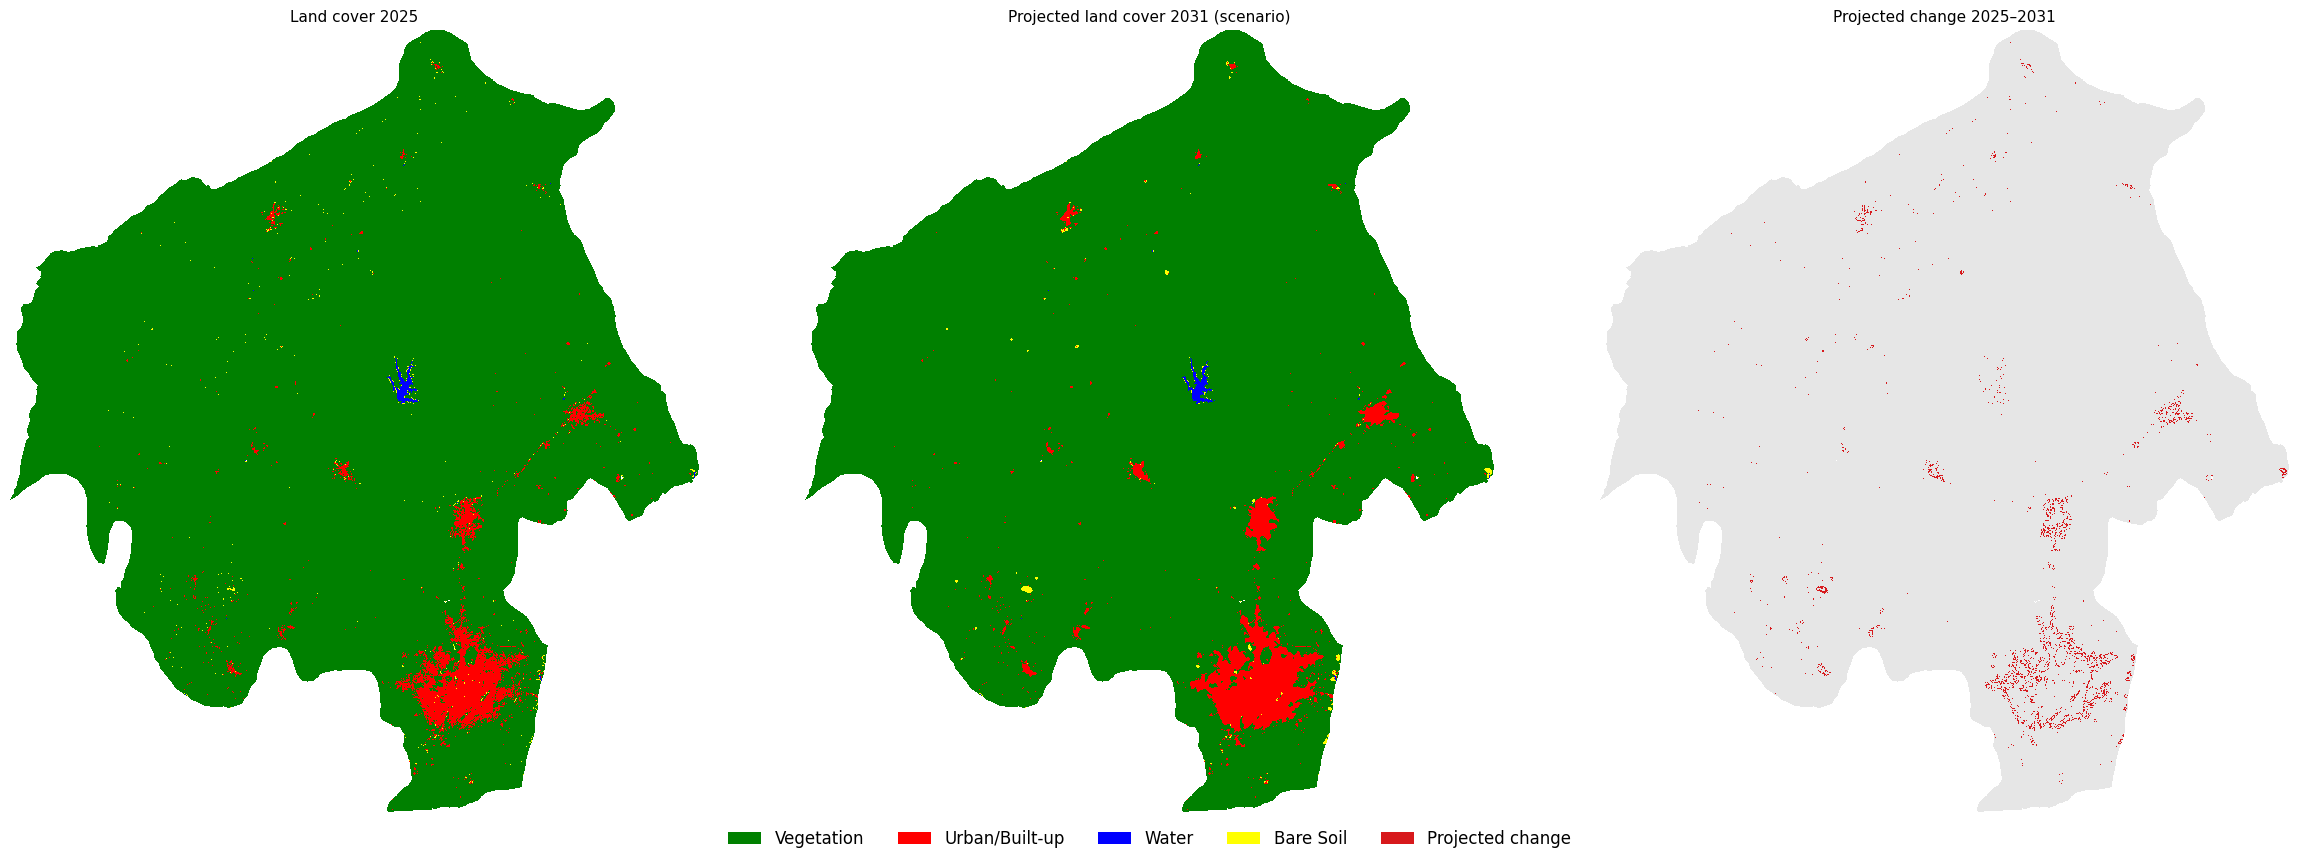

In [ ]:
#  Final projection: calibrate on the full period, project LATEST_YEAR → PROJECTION_YEAR
HORIZON = PROJECTION_YEAR - LATEST_YEAR
P_full = prob_matrix(transition_counts(LC[BASELINE_YEAR], LC[LATEST_YEAR]))
P_proj = apply_rules(rescale_matrix(P_full, HORIZON / span))
display(pd.DataFrame(P_proj, index=[f"from {n}" for n in NAMES], columns=[f"to {n}" for n in NAMES]).round(3))

PROJ = ca_markov_project(LC[LATEST_YEAR], P_proj)
PROJ_CHANGE = np.where((LC[LATEST_YEAR] > 0) & (PROJ > 0), LC[LATEST_YEAR] * 10 + PROJ, 0).astype(np.uint8)

# Area table
cnt_last, cnt_proj = class_counts(LC[LATEST_YEAR]), class_counts(PROJ)
proj_df = pd.DataFrame({f"area_{LATEST_YEAR}_km2": cnt_last * PIXEL_KM2,
                        f"area_{PROJECTION_YEAR}_projected_km2": cnt_proj * PIXEL_KM2}, index=NAMES)
proj_df["net_change_km2"] = proj_df.iloc[:, 1] - proj_df.iloc[:, 0]
proj_df["net_change_%"] = 100 * proj_df["net_change_km2"] / proj_df.iloc[:, 0]

# Uncertainty: alternative calibration periods (Markov expectation only)
scenarios = {}
for label, (y0, y1) in {f"Full period {BASELINE_YEAR}–{LATEST_YEAR}": (BASELINE_YEAR, LATEST_YEAR),
                        f"Recent {YEARS[3]}–{LATEST_YEAR}": (YEARS[3], LATEST_YEAR),
                        f"Early {BASELINE_YEAR}–{HC_START}": (BASELINE_YEAR, HC_START)}.items():
    P_s = apply_rules(rescale_matrix(prob_matrix(transition_counts(LC[y0], LC[y1])), HORIZON / (y1 - y0)))
    scenarios[label] = (cnt_last @ P_s) * PIXEL_KM2
scen_df = pd.DataFrame(scenarios, index=NAMES)
proj_df["scenario_min_km2"], proj_df["scenario_max_km2"] = scen_df.min(axis=1), scen_df.max(axis=1)
proj_df.round(2).to_csv(OUTPUT_DIR / f"projected_area_{LATEST_YEAR}_{PROJECTION_YEAR}.csv")
display(proj_df.round(1))
display(scen_df.round(1).rename_axis("Markov scenarios, km²"))

# LGA-level projection
lga_proj = lga_class_km2(PROJ)
lga_df[f"urban_{PROJECTION_YEAR}_projected_km2"] = lga_df["LGA"].map(dict(zip(LGA_NAMES, lga_proj[:, U])))
lga_df[f"projected_urban_gain_{LATEST_YEAR}_{PROJECTION_YEAR}_km2"] = (
    lga_df[f"urban_{PROJECTION_YEAR}_projected_km2"] - lga_df[f"urban_{LATEST_YEAR}_km2"])
lga_df.round(2).to_csv(OUTPUT_DIR / "lga_statistics_with_projection.csv", index=False)
print(f"LGAs projected to see the largest built-up growth, {LATEST_YEAR}–{PROJECTION_YEAR}:")
display(lga_df.sort_values(f"projected_urban_gain_{LATEST_YEAR}_{PROJECTION_YEAR}_km2", ascending=False)
        [["LGA", f"urban_{LATEST_YEAR}_km2", f"urban_{PROJECTION_YEAR}_projected_km2",
          f"projected_urban_gain_{LATEST_YEAR}_{PROJECTION_YEAR}_km2"]].head(10).round(2))

# Maps
fig, axes = plt.subplots(1, 3, figsize=(24, 8.5))
draw(axes[0], LC[LATEST_YEAR], f"Land cover {LATEST_YEAR}")
draw(axes[1], PROJ, f"Projected land cover {PROJECTION_YEAR} (scenario)")
chg = ((PROJ_CHANGE > 0) & (PROJ_CHANGE // 10 != PROJ_CHANGE % 10)).astype(np.uint8) + (PROJ_CHANGE > 0)
draw(axes[2], chg, f"Projected change {LATEST_YEAR}–{PROJECTION_YEAR}",
     lut=make_lut({1: "#E6E6E6", 2: "#D7191C"}))
fig.legend(legend_handles + [plt.Rectangle((0, 0), 1, 1, fc="#D7191C")], NAMES + ["Projected change"],
           loc="lower center", ncol=5, frameon=False, fontsize=12)
plt.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(OUTPUT_DIR / f"Oyo_projection_{PROJECTION_YEAR}.png", dpi=110, bbox_inches="tight")
plt.show()

## 3D built-up development (pydeck / deck.gl)

Built-up fraction is aggregated to 500 m cells and drawn as extruded columns on a Mapbox-style basemap. **Column height = share of the cell that is built-up. Colour = change versus the comparison year** (yellow→red = growth, blue-grey = stable, teal = decline). Use the dropdowns to step through 2018–2025 and the 2031 projection; drag to pan, **right-drag / Ctrl-drag to rotate and tilt**, scroll to zoom.

In [ ]:
K = CELL_BLOCKS
CELL_M = GRID_SCALE * K


def block_mean(mask):
    h, w = mask.shape[0] // K, mask.shape[1] // K
    return mask[:h * K, :w * K].reshape(h, K, w, K).mean(axis=(1, 3), dtype=np.float32)


# Cells that sit mostly inside the AOI
valid_frac = block_mean(LC[LATEST_YEAR] > 0)
cell_ok = valid_frac >= 0.5
rr, cc = np.nonzero(cell_ok)
xs = GRID_TRANSFORM.c + (cc * K + K / 2) * GRID_TRANSFORM.a
ys = GRID_TRANSFORM.f + (rr * K + K / 2) * GRID_TRANSFORM.e
lon, lat = warp_transform(GRID_CRS, "EPSG:4326", xs.tolist(), ys.tolist())
CELL_LON, CELL_LAT = np.round(lon, 5), np.round(lat, 5)


def built_fraction(arr):
    frac = block_mean(arr == 2)[cell_ok] / valid_frac[cell_ok]
    return np.clip(frac, 0, 1).astype(np.float32)


BUILT = {y: built_fraction(LC[y]) for y in YEARS}
BUILT[PROJECTION_YEAR] = built_fraction(PROJ)
print(f"{cell_ok.sum():,} cells of {CELL_M} m | built-up share of mapped area: "
      + ", ".join(f"{y}: {100 * (LC[y] == 2).sum() / (LC[y] > 0).sum():.1f}%" for y in (BASELINE_YEAR, LATEST_YEAR)))

if MAPBOX_TOKEN:
    os.environ["MAPBOX_API_KEY"] = MAPBOX_TOKEN
    MAP_KW = {"map_provider": "mapbox",
              "map_style": {"dark": "mapbox://styles/mapbox/dark-v11", "light": "mapbox://styles/mapbox/light-v11",
                            "satellite": "mapbox://styles/mapbox/satellite-streets-v12"}.get(BASEMAP, BASEMAP)}
else:
    MAP_KW = {"map_provider": "carto", "map_style": "light" if BASEMAP == "light" else "dark"}


def growth_colours(delta):
    gain, loss = delta >= 0.05, delta <= -0.05
    t = np.clip((delta - 0.05) / 0.35, 0, 1)
    r = np.where(gain, 255, np.where(loss, 40, 120))
    g = np.where(gain, 214 - 169 * t, np.where(loss, 190, 140))
    b = np.where(gain, 10 + 75 * t, np.where(loss, 200, 175))
    return r.astype(int), g.astype(int), b.astype(int)


def built_up_deck(year, compare_to):
    f1, f0 = BUILT[year], BUILT[compare_to]
    keep = np.maximum(f1, f0) >= MIN_BUILT_FRACTION
    d = (f1 - f0)[keep]
    r, g, b = growth_colours(d)
    df = pd.DataFrame({"lon": CELL_LON[keep], "lat": CELL_LAT[keep],
                       "height_m": (np.maximum(f1[keep], 0.02) * HEIGHT_M_AT_100PCT).astype(int),
                       "r": r, "g": g, "b": b,
                       "built_pct": np.round(100 * f1[keep]).astype(int),
                       "change_pp": np.round(100 * d).astype(int)})
    layer = pdk.Layer("GridCellLayer", df, get_position="[lon, lat]", get_elevation="height_m",
                      get_fill_color="[r, g, b, 235]", cell_size=CELL_M, coverage=0.88, extruded=True,
                      pickable=True, auto_highlight=True, elevation_scale=1)
    view = pdk.ViewState(latitude=float(CELL_LAT.mean()), longitude=float(CELL_LON.mean()),
                         zoom=7.6, pitch=58, bearing=-18)
    tooltip = {"html": "<b>Built-up:</b> {built_pct}%<br/><b>Change vs " + str(compare_to) + ":</b> {change_pp} pp",
               "style": {"backgroundColor": "#111", "color": "white", "fontSize": "12px"}}
    return pdk.Deck(layers=[layer], initial_view_state=view, tooltip=tooltip, **MAP_KW), len(df)


def legend_html(year, compare_to, n_cells):
    label = f"{year} (projection)" if year == PROJECTION_YEAR else str(year)
    return f"""
<div style="position:absolute;top:12px;left:12px;z-index:9;font:13px/1.45 system-ui,sans-serif;color:#fff;
 background:rgba(15,15,20,.78);padding:12px 14px;border-radius:8px;max-width:270px">
 <div style="font-size:15px;font-weight:600">Oyo State built-up land, {label}</div>
 <div style="opacity:.8;margin-bottom:6px">Change vs {compare_to} · {CELL_M} m cells · {n_cells:,} shown</div>
 <div><span style="display:inline-block;width:12px;height:12px;background:linear-gradient(90deg,#ffd60a,#ff2d55)"></span> Built-up growth</div>
 <div><span style="display:inline-block;width:12px;height:12px;background:#788caf"></span> Stable</div>
 <div><span style="display:inline-block;width:12px;height:12px;background:#28bec8"></span> Decline</div>
 <div style="opacity:.8;margin-top:6px">Height = built-up share of the cell<br/>Right-drag / Ctrl-drag to rotate</div>
</div>"""


def render_page(year, compare_to):
    deck, n_cells = built_up_deck(year, compare_to)
    # Write to a temporary HTML file and read it back to guarantee we get the HTML markup as a string
    temp_path = "temp_deck.html"
    deck.to_html(temp_path, open_browser=False, notebook_display=False)
    with open(temp_path, "r", encoding="utf-8") as f:
        page = f.read()
    try:
        os.remove(temp_path)
    except Exception:
        pass
    return page.replace("</body>", legend_html(year, compare_to, n_cells) + "</body>")


def show_page(page, height=720):
    display(HTML(f'<iframe srcdoc="{html.escape(page, quote=True)}" width="100%" height="{height}" '
                 'style="border:0;border-radius:8px"></iframe>'))


# Standalone HTML files you can open in any browser or share
html_2025 = OUTPUT_DIR / f"Oyo_BuiltUp_3D_{LATEST_YEAR}_vs_{BASELINE_YEAR}.html"
html_2031 = OUTPUT_DIR / f"Oyo_BuiltUp_3D_{PROJECTION_YEAR}_vs_{LATEST_YEAR}.html"
html_2025.write_text(render_page(LATEST_YEAR, BASELINE_YEAR), encoding="utf-8")
html_2031.write_text(render_page(PROJECTION_YEAR, LATEST_YEAR), encoding="utf-8")
print("Saved:", html_2025.name, f"({html_2025.stat().st_size / 1e6:.1f} MB),", html_2031.name,
      f"({html_2031.stat().st_size / 1e6:.1f} MB)")

48,815 cells of 750 m | built-up share of mapped area: 2018: 2.7%, 2025: 2.8%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved: Oyo_BuiltUp_3D_2025_vs_2018.html (0.7 MB), Oyo_BuiltUp_3D_2031_vs_2025.html (0.6 MB)


In [ ]:
# Interactive 3D viewer — choose the year and the comparison year
year_dd = widgets.Dropdown(options=YEARS + [PROJECTION_YEAR], value=LATEST_YEAR, description="Year:")
base_dd = widgets.Dropdown(options=YEARS, value=BASELINE_YEAR, description="Compare to:")
view_out = widgets.Output()


def refresh(_=None):
    with view_out:
        clear_output(wait=True)
        show_page(render_page(year_dd.value, base_dd.value))


year_dd.observe(refresh, "value")
base_dd.observe(refresh, "value")
display(widgets.HBox([year_dd, base_dd]), view_out)
refresh()

## Interactive 2D comparison (Earth Engine tiles)

In [ ]:

# Convert rasterio Affine transform to flat list
transform_list = [
    GRID_TRANSFORM.a,
    GRID_TRANSFORM.b,
    GRID_TRANSFORM.c,
    GRID_TRANSFORM.d,
    GRID_TRANSFORM.e,
    GRID_TRANSFORM.f
]

# Convert NumPy raster to Earth Engine image
proj_ee = geemap.numpy_to_ee(
    PROJ,
    crs="EPSG:32631",
    transform=transform_list
).rename("class")

# Visualization parameters
VIS = {
    "min": 1,
    "max": 4,
    "palette": PALETTE
}

legend = {
    CLASS_NAMES[c]: CLASS_COLORS[c].lstrip("#")
    for c in CLASS_IDS
}

# CREATE MAP USING ESRI BASEMAP (NO OSM TILES)

M = geemap.Map(
    center=[8.1, 3.6],
    zoom=8,
    basemap="Esri.WorldTopoMap"
)

# Split map: 2025 actual vs 2031 projected
M.split_map(
    geemap.ee_tile_layer(
        CLASSIFIED[LATEST_YEAR],
        VIS,
        f"{LATEST_YEAR} Land Cover"
    ),
    geemap.ee_tile_layer(
        proj_ee,
        VIS,
        f"{PROJECTION_YEAR} Projected"
    ),
    left_label=f"{LATEST_YEAR} (Actual)",
    right_label=f"{PROJECTION_YEAR} (Projected)"
)

# Add 2018 baseline
M.add_ee_layer(
    CLASSIFIED[BASELINE_YEAR],
    VIS,
    f"{BASELINE_YEAR} Baseline"
)

# LGA boundaries
style_params = {
    "color": "#333333",
    "fillColor": "#00000000",
    "width": 1.5
}

M.add_ee_layer(
    aoi_fc.style(**style_params),
    {},
    "LGA Boundaries"
)

# LGA labels
M.add_labels(
    data=aoi_fc,
    column=NAME_FIELD if NAME_FIELD else "LGA_Name",
    font_size="10pt",
    font_color="#ffffff",
    font_weight="bold",
    bg_color="#000000aa",
    border_radius="3px",
    padding="2px"
)

# Land-cover legend
M.add_legend(
    title="Land cover",
    legend_dict=legend
)

# Display interactive map
display(M)

Map(center=[8.1, 3.6], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_out_t…

### Map Overlay for Top 10 Expanding LGAs
This map highlights only the top 10 LGAs in Oyo State with the highest historical urban expansion (2018 to 2025), styled with high-visibility boundaries and interactive text labels.

In [ ]:
import geemap
import ee

# Identify the top 10 expanding LGAs based on historical urban gain
top_10_lga_names = lga_df.head(10)["LGA"].tolist()
top_10_indices = [int(name.split("_")[1]) for name in top_10_lga_names]

# Add indexing to FeatureCollection mirroring the logic used in Step 1
_lga_list = aoi_fc.toList(aoi_fc.size())
_indexed = ee.FeatureCollection(
    ee.List.sequence(1, aoi_fc.size()).map(
        lambda i: ee.Feature(_lga_list.get(ee.Number(i).subtract(1))).set("lga_idx", i)
    )
)

# Filter the feature collection to include only the top 10 expanding LGAs
top_10_fc = _indexed.filter(ee.Filter.inList("lga_idx", top_10_indices))

# Create the map using the topo basemap
M_top_10 = geemap.Map(center=[8.1, 3.6], zoom=8, basemap="Esri.WorldTopoMap")

# Visual parameters for the land cover layer
VIS_params = {
    "min": 1,
    "max": 4,
    "palette": PALETTE
}

# Add the 2025 (latest) classified layer as a background reference
M_top_10.add_ee_layer(CLASSIFIED[LATEST_YEAR], VIS_params, f"{LATEST_YEAR} Land Cover")

# Style params to highlight the boundaries of these top 10 expanding LGAs (bold crimson red outline with semi-transparent fill)
highlight_style = {
    "color": "#D7191C",
    "fillColor": "#D7191C22",
    "width": 3.0
}
M_top_10.add_ee_layer(top_10_fc.style(**highlight_style), {}, "Top 10 Expanding LGAs")

# Add labels showing real names on top of the highlighted LGAs
M_top_10.add_labels(
    data=top_10_fc,
    column="LGA_Name",
    font_size="11pt",
    font_color="#ffffff",
    font_weight="bold",
    bg_color="#d7191caa",
    border_radius="4px",
    padding="3px"
)

# Display the customized interactive map
display(M_top_10)

Map(center=[8.1, 3.6], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tr…

## Final deliverables

In [ ]:
def write_raster(arr, name):
    profile = {"driver": "GTiff", "dtype": "uint8", "count": 1, "height": arr.shape[0], "width": arr.shape[1],
               "crs": GRID_CRS, "transform": GRID_TRANSFORM, "nodata": 0, "compress": "lzw"}
    with rasterio.open(OUTPUT_DIR / name, "w", **profile) as dst:
        dst.write(arr.astype(np.uint8), 1)


if SAVE_FINAL_RASTERS:       # only the final products; no Sentinel-2 imagery or intermediate years
    write_raster(LC[BASELINE_YEAR], f"OyoLC_{BASELINE_YEAR}.tif")
    write_raster(LC[LATEST_YEAR], f"OyoLC_{LATEST_YEAR}.tif")
    write_raster(CHANGE_CODE, f"transition_{BASELINE_YEAR}_{LATEST_YEAR}.tif")
    write_raster(PROJ, f"OyoLC_projected_{PROJECTION_YEAR}.tif")

zip_path = OUTPUT_DIR.parent / f"{OUTPUT_DIR.name}_Deliverables.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(OUTPUT_DIR.iterdir()):
        zf.write(p, p.name)
print("Archive:", zip_path, f"({zip_path.stat().st_size / 1e6:.1f} MB)")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {p.name:<62}{p.stat().st_size / 1e6:8.2f} MB")

try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass

Archive: /content/OyoLandCover_2018_2031_Deliverables.zip (0.5 MB)
  OyoLC_2018.tif                                                    0.08 MB
  OyoLC_2025.tif                                                    0.08 MB
  OyoLC_projected_2031.tif                                          0.07 MB
  Oyo_BuiltUp_3D_2025_vs_2018.html                                  0.74 MB
  Oyo_BuiltUp_3D_2031_vs_2025.html                                  0.57 MB
  Oyo_LandCover_2018_2025_panel.png                                 0.10 MB
  Oyo_projection_2031.png                                           0.07 MB
  accuracy_assessment.csv                                           0.00 MB
  annual_land_cover_area_2018_2025.csv                              0.00 MB
  area_trends.png                                                   0.05 MB
  gains_losses_2018_2025.csv                                        0.00 MB
  hindcast_areas.csv                                                0.00 MB
  hindcast_validation

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>